## 1. RGB Color Space

**RGB (Red, Green, Blue)** — аддитивная цветовая модель, в которой цвет каждого пикселя представляется тремя числовыми значениями. Каждый канал определяет интенсивность соответствующего цвета: красного, зелёного или синего.

В стандартном 8-битном RGB каждый канал принимает значения от 0 до 255, где 0 означает отсутствие соответствующего цветового компонента, а 255 — его максимальную интенсивность.

Изображение в RGB можно представить как **три двумерные матрицы одинакового размера**, каждая из которых содержит значения одного цветового канала (R, G или B). Комбинация значений трёх каналов в каждой позиции определяет цвет соответствующего пикселя.

Таким образом, один пиксель в несжатом 8-битном RGB-представлении занимает **24 бита (3 байта)**. При преобразовании такого изображения в NumPy-массив обычно используется dtype('uint8') — беззнаковый целочисленный тип, занимающий 1 байт на значение канала.

В NumPy RGB-изображение обычно представляется трёхмерным массивом формы (height, width, 3), где первые два измерения определяют положение пикселя, а третье — его цветовые каналы.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 
import numpy as np
from PIL import Image
from pathlib import Path
import os
import torch

In [2]:
train_path = Path('../data/splits/train.txt')
images_dir = Path('../VOCdevkit/VOC2012/JPEGImages')
train_files = train_path.read_text().splitlines()


Pytorch : (Channels, Height, Width)

NumPy: (Height, Width, Channels)

In [3]:
img = Image.open(os.path.join(images_dir, train_files[1000]))
n_img = np.array(img)
n_img.shape

(375, 500, 3)

In [4]:
red_channel = n_img[:, :, 0]
green_channel = n_img[:, :, 1]
blue_channel = n_img[:, :, 2]
print(red_channel.shape)
print(green_channel.shape)
print(blue_channel.shape)

(375, 500)
(375, 500)
(375, 500)


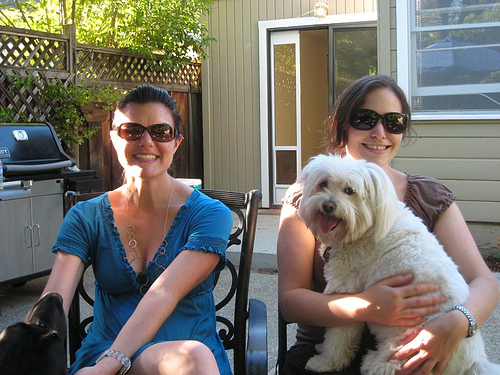

In [5]:
img

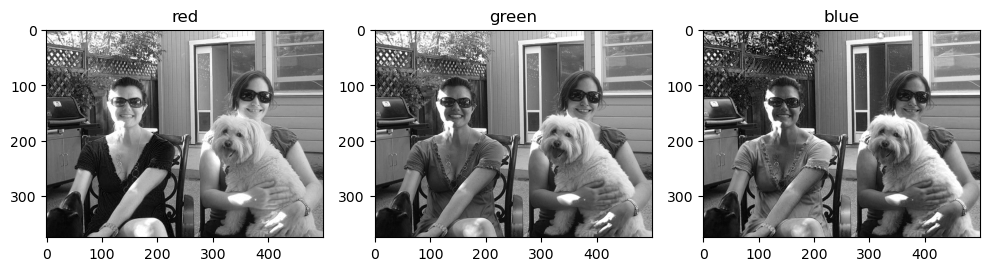

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(10, 8))
ax = ax.flatten()
channels_name = ['red', 'green', 'blue']
for i in range(3):
    ax[i].imshow(n_img[:, :, i], cmap='gray')
    ax[i].set_title(channels_name[i])
plt.tight_layout()
plt.show()


Один канал — это просто одна матрица чисел, а не полноценное цветное изображение. Поэтому смотрим чб визуализацию для каждого из каналов. Чем ближе оттенок к черному тем меньше интенсивность соответствующего цветового канала

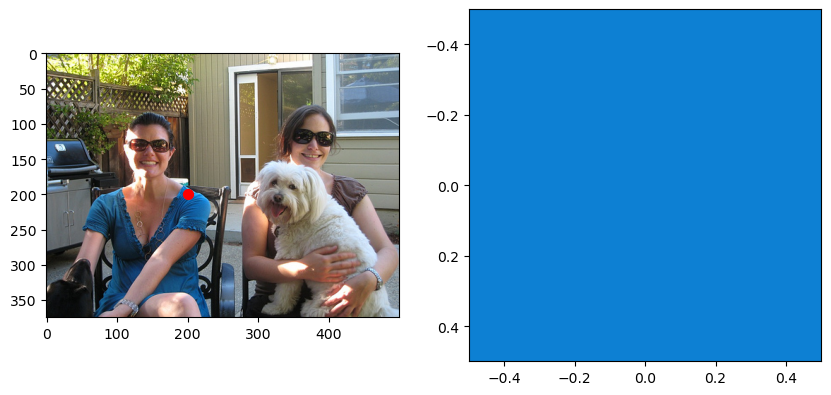

In [7]:
#imshow для RGB ожидает (H, W, 3)
figure, ax = plt.subplots(1, 2, figsize=(10, 8))
ax[0].imshow(n_img)
ax[0].scatter(200, 200, color='red', s=50)

ax[1].imshow(n_img[200:201, 200:201])

plt.show()

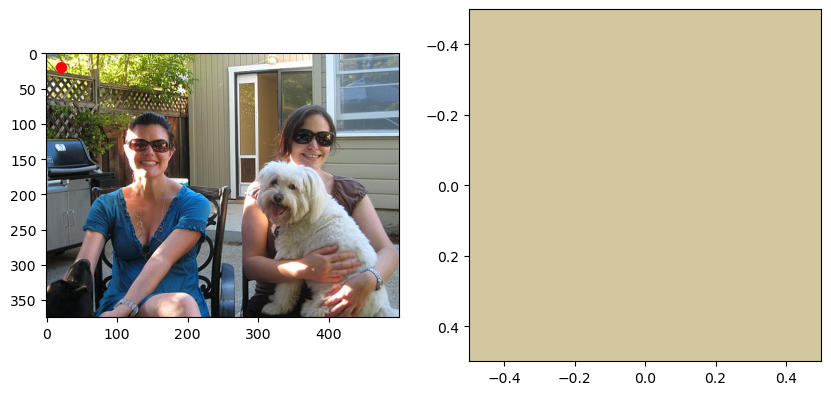

In [8]:
figure, ax = plt.subplots(1, 2, figsize=(10, 8))
ax[0].imshow(n_img)
ax[0].scatter(20, 20, color='red', s=50)

ax[1].imshow(n_img[20:21, 20:21])
plt.show()

# 2. Grayscale

У нас есть цветные фотографи. Мы хотим убрать из них цвет и потом подать изображение с одним каналом в нейросеть, что бы она научилась восстанавливать "утерянную" информацию.
Посмотрим как из трех цветовых каналов получить одно изображение 

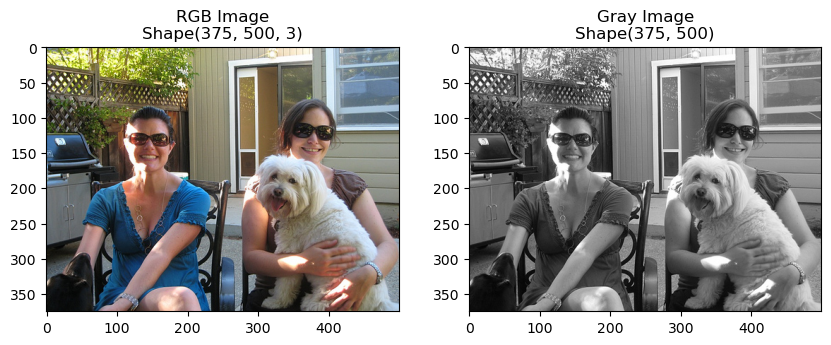

In [9]:
figure, ax = plt.subplots(1, 2, figsize=(10, 8))
ax[0].imshow(n_img)
ax[0].set_title(f"RGB Image\nShape{n_img.shape}")

ax[1].imshow(img.convert('L'), cmap='gray')
ax[1].set_title(f"Gray Image\nShape{np.array(img.convert('L')).shape}")
plt.show()


В результате преобразования каждый пиксель стал описываться одним числом.
В Pillow для обычного преобразования RGB → L используется взвешенная сумма:

$$
Y = 0.299R + 0.587G + 0.114B
$$

Самый большой вес мы даем зеленому каналу, потому что глаз человека воспринимает яркость разных цветов не одинаково. 
Заметим что цветовую информацию мы теряем, и однозначно восстановить первоначальные RGB-значения тяжело, поскольку мы напрямую сжимаем инофрмацию до 1 канала. 

Преобразование RGB → Grayscale не совсем нам подходит

# 3. LAB Color Space

Когда мы делаем преобразование RGB → LAB мы не терям инофмацию о двух каналах. Мы всего лишь меняем представление этих цветов(разделяем информацию о светлоте (L) и цвете (a, b)).  То есть у нас как было три числа на пиксель, так и осталось три.

Посмотрим сначала на то, как будут менятся характеристики одного изображения

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


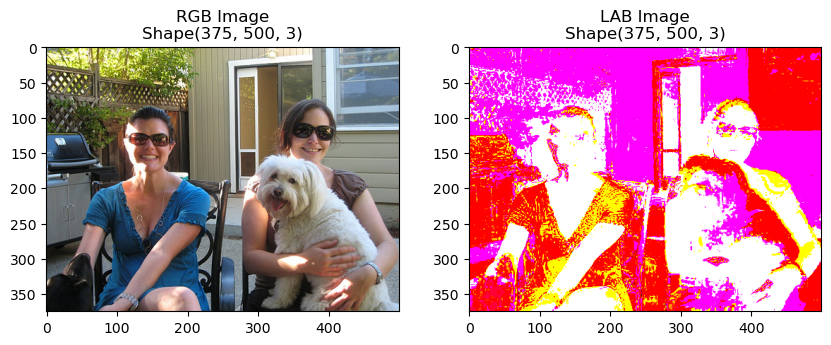

In [10]:
from skimage.color import rgb2lab, lab2rgb

lab_img = rgb2lab(img)

figure, ax = plt.subplots(1, 2, figsize=(10, 8))
ax[0].imshow(n_img)
ax[0].set_title(f"RGB Image\nShape{n_img.shape}")

ax[1].imshow(np.array(lab_img))
ax[1].set_title(f"LAB Image\nShape{np.array(lab_img).shape}")
plt.show()

# 4. Normalization

После преобразования RGB → LAB размерность изображения осталась прежней `(375, 500, 3)`, однако теперь каналы содержат другую информацию

Matplotlib ожидает RGB-значения от 0 до 1 для вещественных чисел, а LAB имеет другие диапазоны значений (обычно приблизительно [−128;127]). Поэтому при прямом выводе через `imshow()` получаем некорректные цвета

Для преобразования RGB → LAB также можно использовать OpenCV (`cv2`) или библиотеку Albumentations, которая работает с OpenCV

Однако при работе с изображениями типа `uint8` OpenCV дополнительно масштабирует и сдвигает значения каналов:

$$
L_{cv2} = L_{real} \times \frac{255}{100}
$$

$$
a_{cv2} = a_{real} + 128
$$

$$
b_{cv2} = b_{real} + 128
$$

В обычном LAB значения `a = 0` и `b = 0` соответствуют нейтральному серому цвету, а отрицательные и положительные значения определяют направление цвета по соответствующим осям. В OpenCV для `uint8` значения `a` и `b` сдвигаются в положительный диапазон

Это не мешает использовать OpenCV для колоризации, но перед обучением модели необходимо правильно обработать диапазоны каналов

В нашем проекте будем использовать `skimage.color.rgb2lab()`, поскольку он возвращает вещественные значения LAB без такого сдвига. Это удобнее для последующей нормализации и обучения U-Net, которая будет предсказывать каналы `a` и `b`

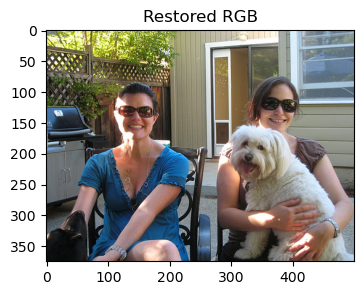

In [11]:
#проверим, что мы правильно преобразуем изображение и не теряем цветовую информацию
rgb_restored = lab2rgb(lab_img)
plt.figure(figsize=(5, 3))
plt.imshow(rgb_restored)
plt.title('Restored RGB')
plt.show()

In [12]:
L = lab_img[:, :, 0]
A = lab_img[:, :, 1]
B = lab_img[:, :, 2]

print(f"Диапозон L канала LABimage: ({L.max()}, {L.min()})")
print(f"Диапозон A канала LABimage: ({A.max()}, {A.min()})")
print(f"Диапозон B канала LABimage: ({B.max()}, {B.min()})")

Диапозон L канала LABimage: (100.0, 0.0)
Диапозон A канала LABimage: (58.29368434089771, -38.209255582208776)
Диапозон B канала LABimage: (83.72940089466307, -58.39629326406397)



Для нормализации LAB используем фиксированные коэффициенты, основываясь на общих диапазонах цветового пространства. 

Канал L имеет диапазон [0, 100], поэтому делим его на 100. Каналы a и b имеют приблизительный диапазон [-128, 128], поэтому делим их на 128.

$$
L_{norm} = \frac{L}{100}, \quad a_{norm} = \frac{a}{128}, \quad b_{norm} = \frac{b}{128}
$$

В результате L принимает значения от 0 до 1, а каналы a и b — приблизительно от -1 до 1. При этом 128 не является строгой границей значений a и b.

Используем одинаковые коэффициенты для всех изображений, чтобы одинаковые цвета имели одинаковые нормализованные значения независимо от фотографии. Перед обратным преобразованием LAB → RGB необходимо выполнить денормализацию.


Диапозон L канала LABimage: (1.0, 0.0)
Диапозон A канала LABimage: (0.4554194089132634, -0.29850980923600606)
Диапозон B канала LABimage: (0.6541359444895553, -0.45622104112549977)


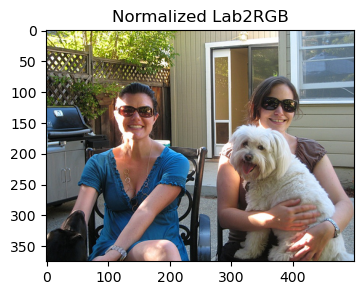

In [13]:
L_norm = L/100
A_norm = A/128
B_norm = B/128
print(f"Диапозон L канала LABimage: ({L_norm.max()}, {L_norm.min()})")
print(f"Диапозон A канала LABimage: ({A_norm.max()}, {A_norm.min()})")
print(f"Диапозон B канала LABimage: ({B_norm.max()}, {B_norm.min()})")

denorm_img = lab2rgb(np.stack([L_norm*100, A_norm*128, B_norm*128], axis=2))
plt.figure(figsize=(5, 3))
plt.imshow(denorm_img)
plt.title('Normalized Lab2RGB')
plt.show()

Численная проверка восстановления изображения

In [14]:
original = n_img.astype(np.float64) / 255

difference = np.abs(original - denorm_img)

print("Максимальная ошибка:", difference.max())
print("Средняя ошибка:", difference.mean())

Максимальная ошибка: 6.029773672172611e-07
Средняя ошибка: 1.8020920868726554e-12


# 5. Color Utilities Validation

In [15]:
#потом исправим на устанавливаемы модули
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.color_utils import normalize_lab, denormalize_lab, prepare_lab

In [16]:
L_norm, ab_norm = prepare_lab(n_img)

print(L_norm.shape)
print(ab_norm.shape)

(375, 500)
(375, 500, 2)


In [17]:
L_norm, ab_norm = prepare_lab(n_img)

lab_restored = denormalize_lab(L_norm, ab_norm)
rgb_restored = lab2rgb(lab_restored)

original = n_img.astype(np.float64) / 255

print("Максимальная ошибка:", np.max(np.abs(original - rgb_restored)))
print("Средняя ошибка:", np.mean(np.abs(original - rgb_restored)))

Максимальная ошибка: 6.029773672172611e-07
Средняя ошибка: 1.8020920868726554e-12



# Итоги

В ходе работы разобрались с представлением изображений в RGB, выделением отдельных каналов и значениями пикселей. Также рассмотрели преобразования RGB → Grayscale и RGB → LAB.

Для задачи Image Colorization будем использовать LAB, поскольку оно позволяет отдельно работать со светлотой L и цветовыми каналами a, b. Это удобно, так как модели достаточно подавать один канал L, а предсказывать она будет только два недостающих цветовых канала.

Также разобрались с нормализацией и денормализацией LAB и реализовали функции для подготовки и обратного преобразования изображений в `src/color_utils.py`.

Проверили восстановление RGB после всех преобразований. Средняя ошибка составила около $1.8 \times 10^{-12}$, то есть исходное изображение практически полностью восстановилось.

Таким образом, подготовили основные функции для работы с цветовыми каналами, которые дальше будем использовать в `Dataset`.
